# CSE558 Midterm: Wine Reviews

**Our question:** is a wine's score about the wine, or about the critic who tasted it?

Data: Kaggle *Wine Reviews* (zynicide), file `winemag-data-130k-v2.csv` only. Run all cells from top to bottom.

| Section | What it does |
|---|---|
| 0. Setup | imports, settings and the test functions |
| 1. Dataset | load the data and describe the columns |
| 2. Data cleaning | duplicates, missing values, text, outliers, encoding; saves the clean data |
| 3. Before vs after cleaning | what cleaning changed |
| 4. Exploring the data | plots, basic questions and our questions |
| 5. Hypothesis tests | five tests, T1–T5 |
| 6. Limitations | what the results cannot tell us |

## 0. Setup

In [1]:
# Imports, folders, random seed and plot style
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(558)   # random seed; only used to jitter dots in one scatter plot

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
FIG = ROOT / 'figures'
FIG.mkdir(exist_ok=True)

ALPHA = 0.05
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

BLUE, ORANGE, INK, GREY, LIGHT = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3de'
plt.rcParams.update({'figure.dpi': 110, 'savefig.bbox': 'tight', 'font.size': 8,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GREY,
                     'axes.grid': True, 'grid.color': LIGHT, 'axes.axisbelow': True, 'legend.frameon': False})


def save_fig(fig, name):
    """Save a figure as a PDF (for the LaTeX report) and show it."""
    fig.savefig(FIG / f'{name}.pdf')
    plt.show()


def pearson_skew(x):
    """Karl Pearson's skewness coefficient: 3 (mean - median) / SD."""
    return 3 * (x.mean() - x.median()) / x.std()

In [2]:
# Test functions, written with the lecture formulas.
# Each returns a dict: test name, statistic, df, p-value, estimate and its 95% CI.
Z975 = stats.norm.ppf(0.975)   # 1.96


def p_value(dist, stat, side):
    """p-value for H1 = 'two-sided', 'less' or 'greater'."""
    if side == 'two-sided':
        return 2 * dist.sf(abs(stat))
    return dist.cdf(stat) if side == 'less' else dist.sf(stat)


def welch_t(x, y, side='two-sided'):
    """Two-sample t without assuming equal variances (Welch df)."""
    n1, n2 = len(x), len(y)
    v1, v2 = x.var(ddof=1) / n1, y.var(ddof=1) / n2
    est, se = x.mean() - y.mean(), np.sqrt(v1 + v2)
    df = (v1 + v2) ** 2 / (v1 ** 2 / (n1 - 1) + v2 ** 2 / (n2 - 1))
    m = stats.t.ppf(0.975, df) * se
    return dict(test='Welch t', stat=est / se, df=df, p=p_value(stats.t(df), est / se, side),
                est=est, lo=est - m, hi=est + m)


def pooled_t(x, y, side='two-sided'):
    """Two-sample t with one pooled variance, df = n1 + n2 - 2."""
    n1, n2 = len(x), len(y)
    sp2 = ((n1 - 1) * x.var(ddof=1) + (n2 - 1) * y.var(ddof=1)) / (n1 + n2 - 2)
    est, se, df = x.mean() - y.mean(), np.sqrt(sp2 * (1 / n1 + 1 / n2)), n1 + n2 - 2
    m = stats.t.ppf(0.975, df) * se
    return dict(test='pooled t', stat=est / se, df=df, p=p_value(stats.t(df), est / se, side),
                est=est, lo=est - m, hi=est + m)


def f_test(x, y):
    """F = s1^2 / s2^2 with (n1-1, n2-1) df, two-sided; the CI is for the variance ratio."""
    F, d1, d2 = x.var(ddof=1) / y.var(ddof=1), len(x) - 1, len(y) - 1
    p = 2 * min(stats.f.cdf(F, d1, d2), stats.f.sf(F, d1, d2))
    return dict(test='F', stat=F, df=(d1, d2), p=p, est=F,
                lo=F / stats.f.ppf(0.975, d1, d2), hi=F / stats.f.ppf(0.025, d1, d2))


def r_test(x, y, side='two-sided'):
    """t = r sqrt(n-2) / sqrt(1-r^2) with n-2 df; the CI for r uses Fisher's z."""
    n, r = len(x), np.corrcoef(x, y)[0, 1]
    t = r * np.sqrt((n - 2) / (1 - r ** 2))
    h = Z975 / np.sqrt(n - 3)
    return dict(test='t on Pearson r', stat=t, df=n - 2, p=p_value(stats.t(n - 2), t, side),
                est=r, lo=np.tanh(np.arctanh(r) - h), hi=np.tanh(np.arctanh(r) + h))


def z_two_props(k1, n1, k2, n2, side='two-sided'):
    """z for p1 - p2 with the pooled rate under H0; the CI uses the unpooled SE."""
    p1, p2, pp = k1 / n1, k2 / n2, (k1 + k2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return dict(test='two-proportion z', stat=z, df=None, p=p_value(stats.norm, z, side),
                est=p1 - p2, lo=p1 - p2 - Z975 * se, hi=p1 - p2 + Z975 * se)


def chi2_variance(x, var0):
    """One-sample chi-square for a variance: (n-1) s^2 / sigma0^2 with n-1 df, two-sided."""
    n, s2 = len(x), x.var(ddof=1)
    c = (n - 1) * s2 / var0
    p = 2 * min(stats.chi2.cdf(c, n - 1), stats.chi2.sf(c, n - 1))
    return dict(test='chi-square for a variance', stat=c, df=n - 1, p=p, est=s2,
                lo=(n - 1) * s2 / stats.chi2.ppf(0.975, n - 1), hi=(n - 1) * s2 / stats.chi2.ppf(0.025, n - 1))


def decide(p):
    return 'reject H0' if p < ALPHA else 'fail to reject H0'


def df_text(df):
    if df is None:
        return '-'
    if isinstance(df, tuple):
        return f'{df[0]:,}, {df[1]:,}'
    return f'{df:,.0f}'


def show(res):
    """Print one test result on one line."""
    print(f"{res['test']}: statistic = {res['stat']:.3f}, df = {df_text(res['df'])}, "
          f"p = {res['p']:.3g} -> {decide(res['p'])}; estimate = {res['est']:.4f}, "
          f"95% CI [{res['lo']:.4f}, {res['hi']:.4f}]")


def matters(lo, hi, delta):
    """Compare the 95% CI with the smallest difference that matters."""
    if lo >= delta or hi <= -delta:
        return 'matters'
    if -delta < lo and hi < delta:
        return 'does not matter'
    return 'unclear'

## 1. Dataset

**Source:** Kaggle, *Wine Reviews* by zynicide (https://www.kaggle.com/datasets/zynicide/wine-reviews),
scraped from WineEnthusiast in 2017. One row is one published review of one wine. We use only
`winemag-data-130k-v2.csv`. The size check (rows × columns ≥ 3,000,000 after encoding) is at the end of Section 2.

In [3]:
# Load the raw file; its first column is a row number, so it becomes the index
raw = pd.read_csv(DATA / 'winemag-data-130k-v2.csv', index_col=0)
print(f'{raw.shape[0]:,} rows x {raw.shape[1]} columns = {raw.size:,} cells')
raw.head(3)

129,971 rows x 13 columns = 1,689,623 cells


,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm


In [4]:
# Every column: its type, number of distinct values, % missing and real-world meaning
FEATURES = {
    'points':      ('discrete', 'WineEnthusiast score; 80-100 published only; our response'),
    'price':       ('continuous', 'bottle price in US dollars'),
    'country':     ('nominal', 'country the wine is from'),
    'province':    ('nominal', 'state or province, e.g. Washington, Bordeaux'),
    'region_1':    ('nominal', 'wine-growing area inside the province'),
    'region_2':    ('nominal', 'wider area (US only)'),
    'variety':     ('nominal', 'grape variety or blend'),
    'winery':      ('nominal', 'producer'),
    'designation': ('nominal', 'vineyard or cuvee name on the label'),
    'title':       ('text', 'wine name; carries the vintage year'),
    'description': ('text', "the critic's review"),
    'taster_name': ('nominal', 'critic who tasted and scored the wine'),
    'taster_twitter_handle': ('nominal', "critic's Twitter handle"),
}
pd.DataFrame({
    'type': {c: t for c, (t, _) in FEATURES.items()},
    'distinct values': raw.nunique(),
    'missing %': (raw.isna().mean() * 100).round(1),
    'meaning': {c: m for c, (_, m) in FEATURES.items()},
}).loc[list(FEATURES)]

,type,distinct values,missing %,meaning
points,discrete,21,0.0,WineEnthusiast score; 80-100 published only; o...
price,continuous,390,6.9,bottle price in US dollars
country,nominal,43,0.0,country the wine is from
province,nominal,425,0.0,"state or province, e.g. Washington, Bordeaux"
region_1,nominal,1229,16.3,wine-growing area inside the province
region_2,nominal,17,61.1,wider area (US only)
variety,nominal,707,0.0,grape variety or blend
winery,nominal,16757,0.0,producer
designation,nominal,37979,28.8,vineyard or cuvee name on the label
title,text,118840,0.0,wine name; carries the vintage year


## 2. Data cleaning

Each step says: **problem → what we did → why**. The row and column count is recorded after every step
(shown again in Section 3).

In [5]:
# Start from a copy of the raw data and record its size after every cleaning step
df = raw.copy()
log = []


def log_step(step):
    log.append({'step': step, 'rows': len(df), 'columns': df.shape[1]})
    print(f'after "{step}": {len(df):,} rows x {df.shape[1]} columns')


log_step('0 raw file')

after "0 raw file": 129,971 rows x 13 columns


### 2.1 Remove duplicate rows
**Problem:** some rows are exact copies. **What:** drop the copies. **Why:** the same review scraped twice is one
observation; keeping both makes *n* too big and every standard error too small.

In [6]:
# Count rows that are exact copies of an earlier row, then drop them
print(f'exact duplicate rows: {df.duplicated().sum():,}')
df = df.drop_duplicates()
log_step('1 remove duplicate rows')

exact duplicate rows: 9,983


after "1 remove duplicate rows": 119,988 rows x 13 columns


### 2.2 Remove repeated reviews
**Problem:** a few review texts appear on two different rows. **What:** keep the first row of each pair.
**Why:** the titles differ (checked below), so one review was pasted onto two wines. Keeping both would count the
same text twice in T2.

In [7]:
# Find review texts used on two rows, check whether their titles differ, then keep the first row of each
shared = df[df.description.duplicated(keep=False)].sort_values('description')
n_pairs = shared.description.nunique()
titles_differ = (shared.groupby('description').title.nunique() > 1).sum()
print(f'{n_pairs} review texts appear twice; the titles differ in {titles_differ} of them')
display(shared[['title', 'points', 'price', 'taster_name']].head(6))
df = df[~df.description.duplicated(keep='first')].copy()
log_step('2 remove repeated reviews')

33 review texts appear twice; the titles differ in 33 of them


,title,points,price,taster_name
71853,Château Maucaillou 2012 Barrel Sample (Moulis...,91,NaN,Roger Voss
71851,Château Pontac-Lynch 2012 Barrel Sample (Marg...,91,NaN,Roger Voss
105559,Château Gruaud Larose 2012 Barrel Sample (Sai...,93,NaN,Roger Voss
105554,Château Grand-Puy-Lacoste 2012 Barrel Sample ...,93,NaN,Roger Voss
73905,Stefano Accordini 2007 Passo Red (Rosso del Ve...,88,35.0,NaN
73890,Stefano Accordini 2008 Passo Red (Rosso del Ve...,88,35.0,NaN


after "2 remove repeated reviews": 119,955 rows x 13 columns


### 2.3 Remove rows with no country or variety
**Problem:** a handful of rows have no country, and one has no variety. **What:** drop them. **Why:** the tests
group wines by country and variety. Guessing a country would invent data, and there are too few rows to matter.

In [8]:
# Drop the few rows with no country or no variety
print(f'missing country: {df.country.isna().sum()}, missing variety: {df.variety.isna().sum()}')
df = df[df.country.notna() & df.variety.notna()].copy()
log_step('3 remove rows with no country/variety')

missing country: 59, missing variety: 1
after "3 remove rows with no country/variety": 119,895 rows x 13 columns


### 2.4 Fill missing prices
First we check whether a missing price is random or depends on the country, with a χ² test for independence on
*country (top 9 + Other) × price missing*.

In [9]:
# Missing-price rate by country, and a chi-square test: does missingness depend on country?
df['price_imputed'] = df.price.isna()
top9 = df.country.value_counts().index[:9]
country9 = df.country.where(df.country.isin(top9), 'Other')
print(df.groupby(country9).price_imputed.mean().sort_values(ascending=False).round(3).to_string())
chi2_miss, p_miss, dof_miss, _ = stats.chi2_contingency(pd.crosstab(country9, df.price_imputed), correction=False)
print(f'\nchi-square = {chi2_miss:,.1f}, df = {dof_miss}, p = {p_miss:.3g} -> {decide(p_miss)}')

country
France       0.200
Austria      0.164
Portugal     0.143
Italy        0.136
Other        0.033
Chile        0.013
Australia    0.013
Argentina    0.012
Spain        0.011
US           0.004

chi-square = 11,618.3, df = 9, p = 0 -> reject H0


**Problem:** missing prices are **systematic** (they depend strongly on country). **What:** fill each one with the
**median price of the same country**, and flag it in `price_imputed`. **Filled-in prices are left out of every test.**
**Why the median:** prices are right-skewed, so the mean is pulled up by luxury bottles. **Why not delete:** these
rows still have a real score, country and variety, and deleting them would drop the encoded table below
3M cells (shown in 2.12).

In [10]:
# Fill each missing price with its country's median price (the overall median if a country has no prices)
country_median = df.groupby('country').price.transform('median')
df['price'] = df.price.fillna(country_median).fillna(df.price.median())
print(f'filled {df.price_imputed.sum():,} prices')
log_step('4 fill missing prices')

filled 8,384 prices
after "4 fill missing prices": 119,895 rows x 14 columns


### 2.5 Fill missing taster names
**Problem:** about 1 in 5 reviews has no taster, and the rate varies a lot by country (below), so it is not
random. **What:** fill with `"Unknown"`. **Why:** the review and its score exist. Dropping the rows would remove a
large share of some countries' reviews. T4 and T5 use two named critics, so `"Unknown"` never enters them.

In [11]:
# Share of reviews with no taster name, by country; then fill the gaps with "Unknown"
print(df.taster_name.isna().groupby(country9).mean().sort_values(ascending=False).round(3).to_string())
df['taster_name'] = df.taster_name.fillna('Unknown')
log_step('5 fill missing taster names')

country
Italy        0.445
US           0.317
Australia    0.131
Other        0.031
Chile        0.026
France       0.013
Spain        0.010
Austria      0.003
Portugal     0.001
Argentina    0.001
after "5 fill missing taster names": 119,895 rows x 14 columns


### 2.6 Drop unused columns
* `region_2`: mostly missing, and only filled for US wines.
* `taster_twitter_handle`: one handle per taster, so it repeats `taster_name`.
* `winery`, `designation`: thousands of distinct values, so they act like IDs, not groups we can compare.

In [12]:
# Evidence for dropping the four columns, then drop them
print(f"region_2: {df.region_2.isna().mean():.0%} missing; only filled for {df.loc[df.region_2.notna(), 'country'].unique()}")
print(f"twitter handles per taster: at most {df.groupby('taster_name').taster_twitter_handle.nunique().max()}")
print(f"distinct values: winery {df.winery.nunique():,}, designation {df.designation.nunique():,}")
df = df.drop(columns=['region_2', 'taster_twitter_handle', 'winery', 'designation'])
log_step('6 drop 4 columns')

region_2: 61% missing; only filled for ['US']
twitter handles per taster: at most 1
distinct values: winery 16,743, designation 37,950
after "6 drop 4 columns": 119,895 rows x 10 columns


### 2.7 Clean text
**Problem:** double spaces in titles, and a hidden non-breaking space (`\xa0`) in some taster names. **What:**
replace `\xa0` with a normal space and collapse double spaces. **Why:** otherwise a filter such as
`taster_name == "Anne Krebiehl MW"` silently misses rows.

In [13]:
# Replace non-breaking spaces and collapse double spaces in every text column; count the problems before and after
NBSP = '\xa0'
print('before:', df.title.str.contains('  ').sum(), 'titles with double spaces,',
      df.taster_name.str.contains(NBSP).sum(), 'taster names with \\xa0')
for c in df.select_dtypes('object').columns:
    df[c] = df[c].str.replace(NBSP, ' ', regex=False).str.replace(r'\s{2,}', ' ', regex=True).str.strip()
print('after: ', df.title.str.contains('  ').sum(), 'titles with double spaces,',
      df.taster_name.str.contains(NBSP).sum(), 'taster names with \\xa0')
log_step('7 clean text')

before: 26857 titles with double spaces, 3281 taster names with \xa0


after:  0 titles with double spaces, 0 taster names with \xa0
after "7 clean text": 119,895 rows x 10 columns


### 2.8 Get the vintage year from the title
**Problem:** the vintage year is only inside the title text. **What:** find 4-digit years (1900–2099) with a regex.
The vintage is left empty (NaN) when the title has no year, says `NV` (non-vintage), has two different years, or
has a year after 2017 (when the data was scraped). **Why not guess:** a wrong vintage is worse than a missing one.
Numbers like 1810 are founding years in winery names (examples below), so the regex ignores years before 1900.

In [14]:
# Pull the years out of each title; keep a vintage only if there is exactly one year, no "NV", and it is not after 2017
years = df.title.str.findall(r'\b((?:19|20)\d{2})\b').apply(lambda l: sorted(set(map(int, l))))
is_nv = df.title.str.contains(r'\bNV\b')
df['vintage'] = [ys[0] if (not nv and len(ys) == 1 and ys[0] <= 2017) else np.nan
                 for ys, nv in zip(years, is_nv)]

reason = np.select([is_nv, years.str.len() == 0, years.str.len() > 1, df.vintage.isna()],
                   ['NV (non-vintage)', 'no year', 'two different years', 'after 2017'], 'vintage kept')
print(pd.Series(reason).value_counts().to_string())
print('\nNumbers before 1900 are names, not vintages:')
print(df.title[df.title.str.contains(r'\b1[0-8]\d{2}\b')].head(3).to_string())
log_step('8 add vintage')

vintage kept           115529
NV (non-vintage)         4288
two different years        78

Numbers before 1900 are names, not vintages:
213                      MCV 2014 1105 Red (Paso Robles)
339           Cavas Hill NV 1887 Rosado Sparkling (Cava)
604    Príncipe de Viana 2008 Reserva 1423 Red (Navarra)
after "8 add vintage": 119,895 rows x 11 columns


### 2.9 Merge grape names that mean the same thing
**Problem:** the same grape has different names in different countries (Syrah/Shiraz, Pinot Gris/Pinot Grigio,
Grenache/Garnacha). **What:** use one name for each. **Why:** otherwise one grape is split into two groups.

In [15]:
# Rename Shiraz -> Syrah, Pinot Grigio -> Pinot Gris, Garnacha -> Grenache
SYNONYMS = {'Shiraz': 'Syrah', 'Pinot Grigio': 'Pinot Gris', 'Garnacha': 'Grenache'}
n_before = df.variety.nunique()
print(f'rows renamed: {df.variety.isin(SYNONYMS).sum():,}')
df['variety'] = df.variety.replace(SYNONYMS)
print(f'varieties: {n_before} -> {df.variety.nunique()}')
log_step('9 merge grape names')

rows renamed: 2,077
varieties: 701 -> 698
after "9 merge grape names": 119,895 rows x 11 columns


### 2.10 Handle very high prices
We sort the observed prices (filled-in ones left out) and look at a boxplot and a quantile plot. A price is an
outlier if it is above the IQR fence, Q3 + 1.5 × IQR.

In [16]:
# IQR fence for the observed prices, and the ten most expensive bottles
observed = df.loc[~df.price_imputed, 'price']
q1, q3 = observed.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
n_above = (observed > fence).sum()
print(f'Q1 = {q1}, Q3 = {q3}, upper fence = {fence}; {n_above:,} prices are above it')
df.loc[~df.price_imputed].nlargest(10, 'price')[['title', 'price', 'points']]

Q1 = 17.0, Q3 = 42.0, upper fence = 79.5; 6,867 prices are above it


,title,price,points
80290,Château les Ormes Sorbet 2013 Médoc,3300.0,88
15840,Château Pétrus 2014 Pomerol,2500.0,96
98380,Domaine du Comte Liger-Belair 2010 La Romanée,2500.0,96
120391,Blair 2013 Roger Rose Vineyard Chardonnay (Arr...,2013.0,91
65352,Château Pétrus 2011 Pomerol,2000.0,97
113564,Domaine du Comte Liger-Belair 2005 La Romanée,2000.0,96
1558,Château Margaux 2009 Margaux,1900.0,98
111753,Château Lafite Rothschild 2010 Pauillac,1500.0,100
111755,Château Cheval Blanc 2010 Saint-Émilion,1500.0,100
1575,Château Mouton Rothschild 2009 Pauillac,1300.0,96


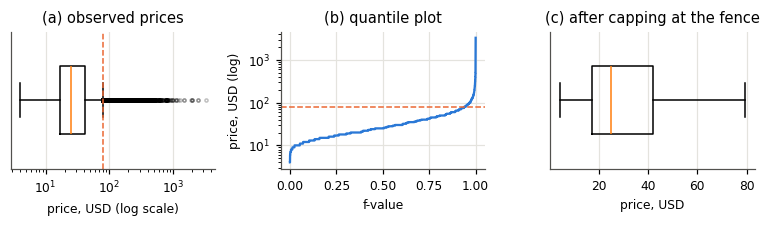

Takeaway: prices are right-skewed; 6,867 bottles sit above the $79.5 fence and run up to $3,300. Capping keeps the rows but removes the long tail.


In [17]:
# Plots: boxplot and quantile plot of observed prices, then the boxplot again after capping at the fence
fig, ax = plt.subplots(1, 3, figsize=(7.0, 2.1))
box = dict(vert=False, widths=0.5, flierprops=dict(marker='o', markersize=2, alpha=0.25))
ax[0].boxplot(observed, **box)
ax[0].set_xscale('log')
ax[0].axvline(fence, color=ORANGE, linestyle='--', linewidth=1)
ax[0].set(title='(a) observed prices', xlabel='price, USD (log scale)', yticks=[])

ax[1].plot((np.arange(len(observed)) + 0.5) / len(observed), np.sort(observed.values), color=BLUE)
ax[1].axhline(fence, color=ORANGE, linestyle='--', linewidth=1)
ax[1].set_yscale('log')
ax[1].set(title='(b) quantile plot', xlabel='f-value', ylabel='price, USD (log)')

ax[2].boxplot(observed.clip(upper=fence), **box)
ax[2].set(title='(c) after capping at the fence', xlabel='price, USD', yticks=[])
fig.tight_layout()
save_fig(fig, 'fig_price_outliers')
print(f'Takeaway: prices are right-skewed; {n_above:,} bottles sit above the ${fence:g} fence and run up to '
      f'${observed.max():,.0f}. Capping keeps the rows but removes the long tail.')

**What:** cap `price` at the fence, and keep the uncapped observed price as `price_raw` (the tests pick price
bands with it). **Why not delete:** these are real luxury bottles (listed above), not typing errors. Capping stops a
few very expensive bottles from dominating an average. Then we **re-check**: compute the fence again on the capped prices and
confirm nothing is above it.

In [18]:
# Cap price at the fence, keep the uncapped price as price_raw, re-check the fence, and compare skewness/kurtosis
df['price_raw'] = df.price.where(~df.price_imputed)   # empty where the price was filled in
df['price'] = df.price.clip(upper=fence)

capped = df.loc[~df.price_imputed, 'price']
cq1, cq3 = capped.quantile([0.25, 0.75])
print('prices above the re-computed fence:', (capped > cq3 + 1.5 * (cq3 - cq1)).sum())
print(pd.DataFrame({'raw': [pearson_skew(observed), stats.kurtosis(observed)],
                    'capped': [pearson_skew(capped), stats.kurtosis(capped)]},
                   index=['Pearson skewness', 'excess kurtosis']).round(2))
log_step('10 cap high prices')

prices above the re-computed fence: 0
                     raw  capped
Pearson skewness    0.76    1.09
excess kurtosis   808.94    0.11
after "10 cap high prices": 119,895 rows x 12 columns


Capping removes the extreme tail (kurtosis falls sharply), but Pearson's skewness goes *up*: the SD shrinks more
than the mean−median gap, because most prices are still right-skewed. So the plots use a log scale, and the tests
compare prices through **price bands**, not through an average price.

### 2.11 Count words in each review
`desc_words` = number of words in the review text. T2 uses it.

In [19]:
# Add desc_words, the word count of each review
df['desc_words'] = df.description.str.split().str.len()
print(df.desc_words.describe().round(1).to_string())
log_step('11 add desc_words')

count    119895.0
mean         40.4
std          11.2
min           3.0
25%          33.0
50%          40.0
75%          47.0
max         135.0
after "11 add desc_words": 119,895 rows x 13 columns


### 2.12 Encode categories and check the size
Encoded table: 5 numeric columns (`points`, `price`, `price_imputed` as 0/1, `vintage`, `desc_words`) +
`country` one-hot (top 9 + Other = 10 columns) + `variety` one-hot (top 10 + Other = 11 columns) = **26 columns**.
Categories are one-hot encoded because numbering them 1, 2, 3… would invent an order. Rare values go into `Other`
because a group of a few dozen wines gives unreliable results.

In [20]:
# One-hot encode country and variety, add the 5 numeric columns, and check rows x columns >= 3,000,000
def top_k(s, k):
    """Keep the k most common values; everything else becomes 'Other'."""
    return s.where(s.isin(s.value_counts().index[:k]), 'Other')


NUMERIC = ['points', 'price', 'price_imputed', 'vintage', 'desc_words']
X = pd.concat([df[NUMERIC].astype(float),
               pd.get_dummies(top_k(df.country, 9), prefix='country', dtype=int),
               pd.get_dummies(top_k(df.variety, 10), prefix='variety', dtype=int)], axis=1)
n, m = X.shape
n_kept = (~df.price_imputed).sum()
print(f'size check: {n:,} rows x {m} columns = {n * m:,} (needs >= 3,000,000)')
print(f'if rows with a missing price were deleted instead: {n_kept:,} x {m} = {n_kept * m:,}, too small')
print('columns:', list(X.columns))
assert m == 26 and n * m >= 3_000_000

size check: 119,895 rows x 26 columns = 3,117,270 (needs >= 3,000,000)
if rows with a missing price were deleted instead: 111,511 x 26 = 2,899,286, too small
columns: ['points', 'price', 'price_imputed', 'vintage', 'desc_words', 'country_Argentina', 'country_Australia', 'country_Austria', 'country_Chile', 'country_France', 'country_Italy', 'country_Other', 'country_Portugal', 'country_Spain', 'country_US', 'variety_Bordeaux-style Red Blend', 'variety_Cabernet Sauvignon', 'variety_Chardonnay', 'variety_Merlot', 'variety_Other', 'variety_Pinot Noir', 'variety_Red Blend', 'variety_Riesling', 'variety_Rosé', 'variety_Sauvignon Blanc', 'variety_Syrah']


In [21]:
# Save the cleaned table and the encoded table; raw_row is the row number in the Kaggle file
df.to_csv(DATA / 'winemag_clean.csv', index_label='raw_row')
X.to_csv(DATA / 'winemag_encoded.csv', index_label='raw_row')
print('saved data/winemag_clean.csv and data/winemag_encoded.csv')

saved data/winemag_clean.csv and data/winemag_encoded.csv


## 3. Before vs after cleaning

In [22]:
# Rows and columns after each cleaning step
pd.DataFrame(log)

,step,rows,columns
0,0 raw file,129971,13
1,1 remove duplicate rows,119988,13
2,2 remove repeated reviews,119955,13
3,3 remove rows with no country/variety,119895,13
4,4 fill missing prices,119895,14
5,5 fill missing taster names,119895,14
6,6 drop 4 columns,119895,10
7,7 clean text,119895,10
8,8 add vintage,119895,11
9,9 merge grape names,119895,11


In [23]:
# Key measures in the raw file vs after cleaning
raw_prices = raw.price.dropna()
rq1, rq3 = raw_prices.quantile([0.25, 0.75])
raw_fence = rq3 + 1.5 * (rq3 - rq1)
pd.DataFrame([
    ('rows', f'{len(raw):,}', f'{len(df):,}'),
    ('columns', f'{raw.shape[1]}', f'{m} after encoding'),
    ('exact duplicate rows', f'{raw.duplicated().sum():,}', '0'),
    ('review texts used twice', f'{n_pairs}', '0'),
    ('missing price', f'{raw.price.isna().sum():,}', f'0 ({df.price_imputed.sum():,} filled and flagged)'),
    ('missing taster_name', f'{raw.taster_name.isna().sum():,}', '0 ("Unknown")'),
    ('grape varieties', f'{raw.variety.nunique()}', f'{df.variety.nunique()}'),
    (f'prices above the ${raw_fence:g} fence', f'{(raw_prices > raw_fence).sum():,}', '0 (capped)'),
    ('price skewness (Pearson)', f'{pearson_skew(raw_prices):.2f}', f'{pearson_skew(capped):.2f}'),
    ('price excess kurtosis', f'{stats.kurtosis(raw_prices):.1f}', f'{stats.kurtosis(capped):.1f}'),
    ('vintage', 'inside the title', f'a number for {df.vintage.notna().sum():,} rows'),
], columns=['measure', 'before', 'after'])

,measure,before,after
0,rows,"129,971","119,895"
1,columns,13,26 after encoding
2,exact duplicate rows,"9,983",0
3,review texts used twice,33,0
4,missing price,"8,996","0 (8,384 filled and flagged)"
5,missing taster_name,"26,244","0 (""Unknown"")"
6,grape varieties,707,698
7,prices above the $79.5 fence,"7,241",0 (capped)
8,price skewness (Pearson),0.76,1.09
9,price excess kurtosis,829.5,0.1


## 4. Exploring the data
From here on we use `T`: the rows with an observed price (filled-in prices left out).

In [24]:
# T = rows with an observed price; every plot and test below uses these rows
T = df[~df.price_imputed].copy()
T['is90'] = T.points >= 90
print(f'{len(T):,} rows')

111,511 rows


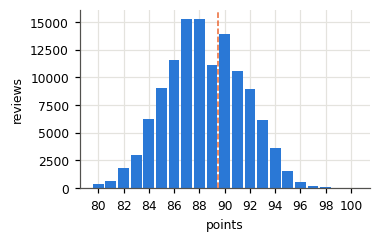

Takeaway: scores run from 80 to 100 (mean 88.4, SD 3.1); nothing is below 80 because lower scores are not published. 38% score 90 or more.


In [25]:
# Histogram of scores
fig, ax = plt.subplots(figsize=(3.4, 2.1))
counts = df.points.value_counts().sort_index()
ax.bar(counts.index, counts.values, width=0.85, color=BLUE)
ax.axvline(89.5, color=ORANGE, linestyle='--', linewidth=1)
ax.set(xlabel='points', ylabel='reviews', xticks=range(80, 101, 2))
save_fig(fig, 'fig_points')
print(f'Takeaway: scores run from 80 to 100 (mean {df.points.mean():.1f}, SD {df.points.std():.1f}); nothing is '
      f'below 80 because lower scores are not published. {(df.points >= 90).mean():.0%} score 90 or more.')

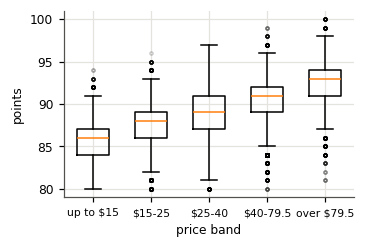

Takeaway: the median score climbs from 86 to 93 across the bands; r(log price, points) = 0.62, so a fair comparison must hold price fixed.


In [26]:
# Scores by price band (boxplots), and the correlation between log(price) and score
BAND_LABELS = ['up to $15', '$15-25', '$25-40', f'$40-{fence:g}', f'over ${fence:g}']
T['price_band'] = pd.cut(T.price_raw, [0, 15, 25, 40, fence, np.inf], labels=BAND_LABELS)

fig, ax = plt.subplots(figsize=(3.4, 2.2))
ax.boxplot([T.points[T.price_band == b] for b in BAND_LABELS], widths=0.55,
           flierprops=dict(marker='o', markersize=2, alpha=0.2))
ax.set_xticks(range(1, 6), [b.replace('$', r'\$') for b in BAND_LABELS], fontsize=7)
ax.set(xlabel='price band', ylabel='points')
save_fig(fig, 'fig_price_points')
medians = T.groupby('price_band', observed=True).points.median()
r_logprice = np.corrcoef(np.log(T.price_raw), T.points)[0, 1]
print(f'Takeaway: the median score climbs from {medians.iloc[0]:g} to {medians.iloc[-1]:g} across the bands; '
      f'r(log price, points) = {r_logprice:.2f}, so a fair comparison must hold price fixed.')

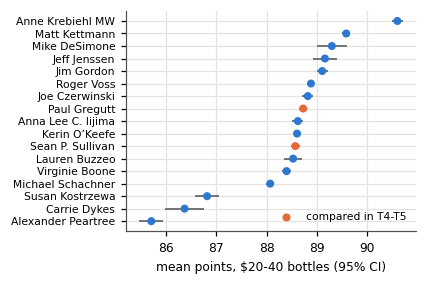

Takeaway: at the same $20-40 price, critics' averages differ by up to 4.9 points: who tastes may matter as much as what is tasted.


In [27]:
# Average score given by each critic to $20-40 bottles (critics with 100+ such reviews), with 95% CIs
mid_price = T[T.price_raw.between(20, 40) & (T.taster_name != 'Unknown')]
by_taster = (mid_price.groupby('taster_name').points.agg(mean='mean', sd='std', n='size')
             .query('n >= 100').sort_values('mean'))
half = stats.t.ppf(0.975, by_taster.n - 1) * by_taster.sd / np.sqrt(by_taster.n)

fig, ax = plt.subplots(figsize=(3.4, 2.6))
colors = [ORANGE if t in ('Paul Gregutt', 'Sean P. Sullivan') else BLUE for t in by_taster.index]
ax.errorbar(by_taster['mean'], range(len(by_taster)), xerr=half, fmt='none', ecolor=GREY, elinewidth=1)
ax.scatter(by_taster['mean'], range(len(by_taster)), c=colors, s=18, zorder=3)
ax.scatter([], [], c=ORANGE, s=18, label='compared in T4-T5')
ax.set_yticks(range(len(by_taster)), by_taster.index, fontsize=7)
ax.set(xlabel='mean points, $20-40 bottles (95% CI)')
ax.legend(loc='lower right', fontsize=7)
save_fig(fig, 'fig_tasters')
print(f"Takeaway: at the same $20-40 price, critics' averages differ by up to "
      f"{by_taster['mean'].max() - by_taster['mean'].min():.1f} points: who tastes may matter as much as what is tasted.")

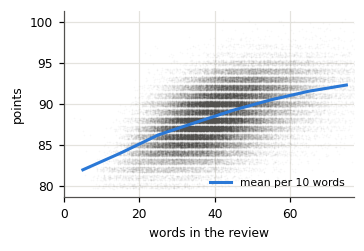

Takeaway: longer reviews come with higher scores (r = 0.54), from about 82 points for the shortest reviews to 92 for the longest.


In [28]:
# Review length vs score: each review is a faint dot (jittered, as both are whole numbers); the line is the mean per 10 words
fig, ax = plt.subplots(figsize=(3.4, 2.2))
ax.scatter(T.desc_words + rng.uniform(-0.45, 0.45, len(T)), T.points + rng.uniform(-0.35, 0.35, len(T)),
           s=1, alpha=0.04, color=GREY, rasterized=True, linewidths=0)
x_max = T.desc_words.quantile(0.995)
binned = T.groupby(pd.cut(T.desc_words, np.arange(0, x_max + 10, 10)), observed=True).points.mean()
ax.plot([b.mid for b in binned.index], binned.values, color=BLUE, linewidth=2, label='mean per 10 words')
ax.set(xlabel='words in the review', ylabel='points', xlim=(0, x_max))
ax.legend(loc='lower right', fontsize=7)
save_fig(fig, 'fig_words')
print(f'Takeaway: longer reviews come with higher scores (r = {np.corrcoef(T.desc_words, T.points)[0, 1]:.2f}), '
      f'from about {binned.iloc[0]:.0f} points for the shortest reviews to {binned.iloc[-1]:.0f} for the longest.')

### Basic questions

In [29]:
# Q1 price vs score, Q2 best-scoring countries, Q3 most-reviewed varieties
print(f'Q1 Do pricier wines score higher? r(log price, points) = {r_logprice:.2f}')
best = (T.groupby('country').points.agg(mean='mean', n='size').query('n >= 500')
        .sort_values('mean', ascending=False))
print('\nQ2 Best-scoring countries (500+ priced reviews):')
print(best.head(5).round(2).to_string())
print('\nQ3 Most-reviewed varieties:')
print(df.variety.value_counts().head(5).to_string())

Q1 Do pricier wines score higher? r(log price, points) = 0.62

Q2 Best-scoring countries (500+ priced reviews):
            mean      n
country                
Austria    90.22   2535
Germany    89.88   1951
France     88.75  16286
Italy      88.63  15492
Australia  88.57   2169

Q3 Most-reviewed varieties:
variety
Pinot Noir                  12274
Chardonnay                  10864
Cabernet Sauvignon           8835
Red Blend                    8229
Bordeaux-style Red Blend     6469


### Our questions
The basic questions look at one column at a time, and price clearly drives the score. Our questions compare
**like with like** (same price, or same state and vintage) and ask whether things that should *not* change a score do:

* **P1 (main question):** for the same kind of wine, does the critic change the score? → T4 (share of 90+) and T5 (spread)
* **P2:** at the same price, do Old-World wines score differently from New-World wines? → T1
* **P3:** is the length of the review a sign of the score? → T2
* **P4:** at what price does a 90+ score become likely? → T3

**Why they are new:** each needs a like-for-like comparison or a column we built ourselves (price band,
Old/New World, vintage, word count). No single column of the raw data answers them.

## 5. Hypothesis tests

All tests use `T` (observed prices only), α = 0.05, and two-sided 95% confidence intervals. With samples this large
almost any difference is "significant", so each test first fixes the **smallest difference that matters** and then
reads the CI against it: **matters** (CI entirely beyond it), **does not matter** (CI entirely inside it) or
**unclear** (CI crosses it).

Each test has three parts: **a)** hypotheses, written before running it; **b)** other tests we considered;
**c)** the result.

### T1: Old World vs New World wines

**a) Written before running the test**

| | |
|---|---|
| Groups | Old World = Europe and the eastern Mediterranean/Caucasus; New World = the Americas, Australia, NZ, South Africa (China, India, Egypt, Morocco left out) |
| Rows | observed price \$20–40 (around the median, where both groups are large) |
| H₀ | μ_Old − μ_New = 0 |
| H₁ | μ_Old − μ_New ≠ 0 |
| α, side | 0.05, two-sided (P2 asks *whether* origin matters, not which way) |
| Test | two-sample t; an F-test for equal variances runs first and decides pooled vs Welch (Welch if F rejects) |
| Smallest difference that matters | **1 point**: scores are whole points, so a smaller gap does not change a typical bottle's printed score |

In [30]:
# Split the $20-40 wines into Old World and New World, and describe both groups
OLD_WORLD = ['Armenia', 'Austria', 'Bosnia and Herzegovina', 'Bulgaria', 'Croatia', 'Cyprus', 'Czech Republic',
             'England', 'France', 'Georgia', 'Germany', 'Greece', 'Hungary', 'Israel', 'Italy', 'Lebanon',
             'Luxembourg', 'Macedonia', 'Moldova', 'Portugal', 'Romania', 'Serbia', 'Slovakia', 'Slovenia',
             'Spain', 'Switzerland', 'Turkey', 'Ukraine']
NEW_WORLD = ['Argentina', 'Australia', 'Brazil', 'Canada', 'Chile', 'Mexico', 'New Zealand', 'Peru',
             'South Africa', 'US', 'Uruguay']
print('countries in neither group:', sorted(set(df.country) - set(OLD_WORLD) - set(NEW_WORLD)))

LO, HI = 20, 40
mid = T[T.price_raw.between(LO, HI)]
old = mid.points[mid.country.isin(OLD_WORLD)]
new = mid.points[mid.country.isin(NEW_WORLD)]
pd.DataFrame({'Old World': old.describe(), 'New World': new.describe()}).T[['count', 'mean', '50%', 'std']].round(3)

countries in neither group: ['China', 'Egypt', 'India', 'Morocco']


,count,mean,50%,std
Old World,18047.0,88.828,89.0,2.390
New World,27929.0,88.232,88.0,2.733


In [31]:
# Step 1: F-test for equal variances. Step 2: Welch t if F rejects, pooled t if not. Then compare the CI with 1 point.
f1 = f_test(old, new)
show(f1)
t1 = welch_t(old, new) if f1['p'] < ALPHA else pooled_t(old, new)
show(t1)
v1 = matters(t1['lo'], t1['hi'], 1.0)
print('verdict vs 1 point:', v1)

F: statistic = 0.765, df = 18,046, 27,928, p = 7.94e-86 -> reject H0; estimate = 0.7648, 95% CI [0.7449, 0.7854]
Welch t: statistic = 24.643, df = 42,033, p = 3.84e-133 -> reject H0; estimate = 0.5955, 95% CI [0.5481, 0.6428]
verdict vs 1 point: does not matter


**b) Other tests considered.** Two independent groups with a numeric score and unknown σ call for a two-sample
t-test.
* *Pooled t-test* assumes equal variances, which the F-test rejects. We run it anyway (below) to compare.
* *Two-sample z-test* needs the population σ. With tens of thousands of wines per group it gives the same answer as t.
* *Paired t-test* does not apply: no wine is in both groups.
* *χ² test for independence* on Old/New × 90+ would throw away the detail in the score.

In [32]:
# Other test: pooled t (assumes equal variances)
show(pooled_t(old, new))

pooled t: statistic = 23.947, df = 45,974, p = 5.86e-126 -> reject H0; estimate = 0.5955, 95% CI [0.5467, 0.6442]


**c) Result.** Old-World wines at \$20–40 score higher than New-World ones, and the difference is significant. But
the whole 95% CI is below 1 point, so **the difference does not matter** in practice. The pooled t agrees.

### T2: Longer reviews vs higher scores

**a) Written before running the test**

| | |
|---|---|
| ρ | Pearson correlation between `desc_words` and `points` |
| H₀ | ρ ≤ 0 (tested at the boundary ρ = 0) |
| H₁ | ρ > 0 |
| α, side | 0.05, one-sided (right): P3 says longer reviews go with *higher* scores |
| Test | t-test on the correlation coefficient, t = r√(n−2)/√(1−r²), df = n − 2 |
| Smallest effect that matters | **ρ = 0.3**: below that, length explains under 9% of the variation in scores |

In [33]:
# t-test on Pearson r between review length and score (one-sided); then compare the CI with 0.3
t2 = r_test(T.desc_words, T.points, side='greater')
show(t2)
v2 = 'matters' if t2['lo'] >= 0.3 else ('does not matter' if t2['hi'] < 0.3 else 'unclear')
print('verdict vs r = 0.3:', v2)

t on Pearson r: statistic = 213.066, df = 111,509, p = 0 -> reject H0; estimate = 0.5379, 95% CI [0.5337, 0.5420]
verdict vs r = 0.3: matters


**b) Other tests considered.** Both variables are numbers measured on the same wine, so the question is about
association. That calls for the t-test on Pearson r (df = n − 2), with a CI from Fisher's z.
* *Welch t on long vs short reviews* (split at the median word count) answers a rougher question, but its result
  is in points, so we run it (below).
* *χ² test for independence* on length bands × 90+ would need arbitrary bins.
* *Paired t* has nothing to pair.

In [34]:
# Other test: Welch t, scores of reviews longer vs not longer than the median word count
long_reviews = T.points[T.desc_words > T.desc_words.median()]
short_reviews = T.points[T.desc_words <= T.desc_words.median()]
show(welch_t(long_reviews, short_reviews, side='greater'))

Welch t: statistic = 160.406, df = 108,743, p = 0 -> reject H0; estimate = 2.6940, 95% CI [2.6611, 2.7269]


**c) Result.** The correlation is clearly positive and its whole CI is above 0.3, so **it matters**: longer reviews
go with higher scores. The cause is unknown; most likely critics write more about wines they like (see Limitations).

### T3: Price band vs the chance of a 90+ score

**a) Written before running the test**

| | |
|---|---|
| Table | price band (up to \$15, \$15–25, \$25–40, \$40–79.5, over \$79.5; the last cut is the IQR fence) × 90+ (yes/no) |
| H₀ | 90+ is independent of price band (the same 90+ share in every band) |
| H₁ | the 90+ share differs between bands |
| α, side | 0.05; χ² uses the upper tail |
| Test | χ² test for independence, expected count = row total × column total / grand total, df = (5−1)(2−1) = 4 |
| Smallest difference that matters | **5 percentage points** in 90+ share between neighbouring bands (one more 90+ bottle in every twenty) |

In [35]:
# Chi-square test for independence: price band x 90+, with expected counts computed by hand
obs3 = pd.crosstab(T.price_band, T.is90)
expected3 = np.outer(obs3.sum(axis=1), obs3.sum(axis=0)) / obs3.values.sum()
chi2_3 = ((obs3.values - expected3) ** 2 / expected3).sum()
dof3 = (obs3.shape[0] - 1) * (obs3.shape[1] - 1)
p3 = stats.chi2.sf(chi2_3, dof3)
print(obs3)
print(f'smallest expected count = {expected3.min():,.0f}')
print(f'chi-square = {chi2_3:,.1f}, df = {dof3}, p = {p3:.3g} -> {decide(p3)}')

is90        False  True 
price_band              
up to $15   22066   1190
$15-25      25370   7759
$25-40      14120  11864
$40-79.5     6883  15392
over $79.5    974   5893
smallest expected count = 2,592
chi-square = 30,191.9, df = 4, p = 0 -> reject H0


In [36]:
# 90+ share in each band with its 95% CI, and the step up from the previous band (is it at least 5 points?)
k3, n3 = obs3[True], obs3.sum(axis=1)
share = k3 / n3
half3 = Z975 * np.sqrt(share * (1 - share) / n3)
steps = [z_two_props(k3.iloc[i + 1], n3.iloc[i + 1], k3.iloc[i], n3.iloc[i]) for i in range(4)]
v3 = f"{sum(matters(r['lo'], r['hi'], 0.05) == 'matters' for r in steps)} of 4 steps matter"
print(v3)
pd.DataFrame({
    'n': n3,
    '90+ share %': (100 * share).round(1),
    '95% CI': [f'{100 * (s - h):.1f} to {100 * (s + h):.1f}' for s, h in zip(share, half3)],
    'step up (95% CI)': ['-'] + [f"+{100 * r['est']:.1f} pp ({100 * r['lo']:.1f} to {100 * r['hi']:.1f})" for r in steps],
    'verdict vs 5 pp': ['-'] + [matters(r['lo'], r['hi'], 0.05) for r in steps],
})

4 of 4 steps matter


,n,90+ share %,95% CI,step up (95% CI),verdict vs 5 pp
price_band,,,,,
up to $15,23256,5.1,4.8 to 5.4,-,-
$15-25,33129,23.4,23.0 to 23.9,+18.3 pp (17.8 to 18.8),matters
$25-40,25984,45.7,45.1 to 46.3,+22.2 pp (21.5 to 23.0),matters
$40-79.5,22275,69.1,68.5 to 69.7,+23.4 pp (22.6 to 24.3),matters
over $79.5,6867,85.8,85.0 to 86.6,+16.7 pp (15.7 to 17.7),matters


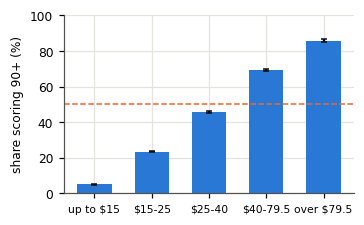

Takeaway: the chance of a 90+ score rises from 5% to 86% and first passes one half in the $40-79.5 band.


In [37]:
# Bar chart of the 90+ share per band, with 95% CIs and a line at one half
fig, ax = plt.subplots(figsize=(3.4, 2.1))
ax.bar(range(5), 100 * share.values, width=0.6, color=BLUE)
ax.errorbar(range(5), 100 * share.values, yerr=100 * half3.values, fmt='none', ecolor=INK, capsize=2)
ax.axhline(50, color=ORANGE, linestyle='--', linewidth=1)
ax.set_xticks(range(5), [b.replace('$', r'\$') for b in BAND_LABELS], fontsize=7)
ax.set(ylabel='share scoring 90+ (%)', ylim=(0, 100))
save_fig(fig, 'fig_band90')
print(f'Takeaway: the chance of a 90+ score rises from {100 * share.iloc[0]:.0f}% to {100 * share.iloc[-1]:.0f}% '
      f'and first passes one half in the {share[share > 0.5].index[0]} band.')

**b) Other tests considered.** Both variables are categories and there are five bands, which calls for the χ²
test for independence; every expected count is far above 5 (printed above). A χ² test has no single estimate with a
CI, so the table above gives each band's share and each step between bands, with 95% CIs.
* *z-test for two proportions*, top band vs bottom band, uses only two of the five bands, but it gives a CI in
  percentage points, so we run it (below).
* *χ² goodness of fit* needs an expected distribution of 90+ across bands, and we have none.

In [38]:
# Other test: z-test for two proportions, top band vs bottom band
show(z_two_props(k3.iloc[-1], n3.iloc[-1], k3.iloc[0], n3.iloc[0]))

two-proportion z: statistic = 138.554, df = -, p = 0 -> reject H0; estimate = 0.8070, 95% CI [0.7983, 0.8157]


**c) Result.** The chance of a 90+ score depends on the price band. Every step up between neighbouring bands is
more than 5 percentage points, with its whole CI beyond that, so **every step matters**. A 90+ score first becomes
more likely than not in the \$40–79.5 band, which answers P4.

### T4: Two critics, same kind of wine: share of 90+ scores

Paul Gregutt and Sean P. Sullivan both review **Washington** wines. To compare like with like we take the same
state and the same \$20–40 band. The two critics reviewed in different years (plot below), so we also keep only
**vintages both reviewed at least 25 times**. Otherwise a difference between critics could be a difference
between vintages.

vintages both reviewed 25+ times: [2009, 2010, 2011, 2012]


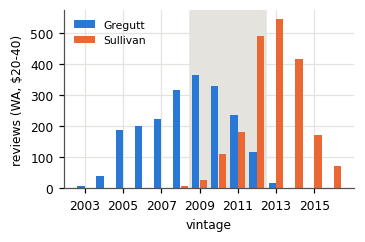

Takeaway: the two critics reviewed Washington at different times; only 2009-2012 (shaded) has 25+ wines from both, so T4 and T5 use only those vintages.


In [39]:
# Washington $20-40 wines by Gregutt or Sullivan: reviews per vintage; keep vintages both reviewed 25+ times
PAIR = ['Paul Gregutt', 'Sean P. Sullivan']
wa = T[(T.province == 'Washington') & T.price_raw.between(LO, HI) & T.taster_name.isin(PAIR)]
vint = pd.crosstab(wa.vintage, wa.taster_name)[PAIR]
common = vint[(vint >= 25).all(axis=1)].index
print('vintages both reviewed 25+ times:', [int(v) for v in common])

shown = vint.loc[2003:2016]
fig, ax = plt.subplots(figsize=(3.4, 2.1))
ax.axvspan(common.min() - 0.5, common.max() + 0.5, color=LIGHT)
ax.bar(shown.index - 0.2, shown[PAIR[0]], width=0.38, color=BLUE, label='Gregutt')
ax.bar(shown.index + 0.2, shown[PAIR[1]], width=0.38, color=ORANGE, label='Sullivan')
ax.set(xlabel='vintage', ylabel='reviews (WA, $20-40)', xticks=shown.index[::2].astype(int))
ax.legend(loc='upper left', fontsize=7)
save_fig(fig, 'fig_wa_vintages')
print(f'Takeaway: the two critics reviewed Washington at different times; only {int(common.min())}-'
      f'{int(common.max())} (shaded) has 25+ wines from both, so T4 and T5 use only those vintages.')

**a) Written before running the test**

| | |
|---|---|
| Rows | Washington, observed price \$20–40, the shared vintages above |
| p_G, p_S | share of 90+ scores given by Gregutt and by Sullivan |
| H₀ | p_G − p_S = 0 |
| H₁ | p_G − p_S ≠ 0 |
| α, side | 0.05, two-sided (no reason to expect either critic to be the more generous) |
| Test | z-test for two proportions, pooled rate under H₀ |
| Smallest difference that matters | **5 percentage points**: one more 90+ label in every twenty bottles |

In [40]:
# z-test for two proportions: share of 90+ scores, Gregutt vs Sullivan; then compare the CI with 5 points
like = wa[wa.vintage.isin(common)]
g = like.points[like.taster_name == PAIR[0]]
s = like.points[like.taster_name == PAIR[1]]
k1, n1, k2, n2 = (g >= 90).sum(), len(g), (s >= 90).sum(), len(s)
print(f'Gregutt: {k1}/{n1} = {k1 / n1:.3f}   Sullivan: {k2}/{n2} = {k2 / n2:.3f}')
both = set(like.title[like.taster_name == PAIR[0]]) & set(like.title[like.taster_name == PAIR[1]])
print(f'wines scored by both critics: {len(both)} of {like.title.nunique():,}')
t4 = z_two_props(k1, n1, k2, n2)
show(t4)
v4 = matters(t4['lo'], t4['hi'], 0.05)
print('verdict vs 5 pp:', v4)

Gregutt: 516/1047 = 0.493   Sullivan: 305/806 = 0.378
wines scored by both critics: 1 of 1,851
two-proportion z: statistic = 4.916, df = -, p = 8.85e-07 -> reject H0; estimate = 0.1144, 95% CI [0.0693, 0.1596]
verdict vs 5 pp: matters


**b) Other tests considered.** The two critics scored almost entirely different wines (overlap printed above), so
the groups are independent, and the outcome is yes/no. That calls for the z-test for two proportions. Each group has
far more than 10 scores on each side of 90, so the normal approximation holds.
* *χ² test for independence* on the 2×2 table (critic × 90+) is the same test (z² = χ²) but gives no signed CI.
  We run it to confirm (below).
* *Welch t on the mean score* compares the whole score, not the 90+ line, so it answers a different question.
* *Paired t* would need the same wines scored by both critics; almost none are.

In [41]:
# Other test: chi-square test on the 2x2 table (critic x 90+); it should equal z squared
chi2_4, p_chi2_4, _, _ = stats.chi2_contingency([[k1, n1 - k1], [k2, n2 - k2]], correction=False)
print(f'chi-square = {chi2_4:.2f} (z squared = {t4["stat"] ** 2:.2f}), p = {p_chi2_4:.3g}')

chi-square = 24.16 (z squared = 24.16), p = 8.85e-07


**c) Result.** For the same kind of wine (same state, price band and vintages), Gregutt gives 90+ more often than
Sullivan. The whole CI is above 5 percentage points, so **the critic effect matters**. The χ² test agrees exactly
(z² = χ²). Vintage cannot explain the gap, because both critics are compared on the same vintages.

### T5: Two critics, same kind of wine: spread of scores

**a) Written before running the test** (same rows as T4)

| | |
|---|---|
| σ²_G, σ²_S | variance of the scores given by Gregutt and by Sullivan |
| H₀ | σ²_G / σ²_S = 1 |
| H₁ | σ²_G / σ²_S ≠ 1 |
| α, side | 0.05, two-sided |
| Test | F-test for two variances, F = s²_G / s²_S, df = (n_G − 1, n_S − 1) |
| Smallest difference that matters | an **SD ratio of 1.2**: one critic's scores spread 20% wider, about half a point, enough to push wines across the 90 line |

In [42]:
# F-test for two variances (Gregutt / Sullivan); then compare the CI for the SD ratio with 1.2
t5 = f_test(g, s)
show(t5)
sd_lo, sd_hi = np.sqrt(t5['lo']), np.sqrt(t5['hi'])
print(f'SD: Gregutt {g.std():.3f}, Sullivan {s.std():.3f}; SD ratio {np.sqrt(t5["est"]):.3f}, '
      f'95% CI [{sd_lo:.3f}, {sd_hi:.3f}]')
v5 = matters(np.log(sd_lo), np.log(sd_hi), np.log(1.2))
print('verdict vs SD ratio 1.2:', v5)

F: statistic = 1.399, df = 1,046, 805, p = 5.54e-07 -> reject H0; estimate = 1.3985, 95% CI [1.2273, 1.5919]
SD: Gregutt 2.539, Sullivan 2.147; SD ratio 1.183, 95% CI [1.108, 1.262]
verdict vs SD ratio 1.2: unclear


**b) Other tests considered.** The question is about spread, not the average, in two independent groups, which
calls for the F-test for two variances. The F-test assumes roughly normal scores; the Q-Q plots below check that.
* *χ² test for one variance* tests Sullivan's variance against a fixed value, here Gregutt's sample variance treated
  as exact. That ignores the uncertainty in Gregutt's own variance, which is why we prefer F. We run it (below).
* *z and t tests* compare averages, not spreads.

In [43]:
# Other test: chi-square test for one variance (Sullivan's variance vs Gregutt's, treated as known)
show(chi2_variance(s, g.var(ddof=1)))

chi-square for a variance: statistic = 575.602, df = 805, p = 2.07e-10 -> reject H0; estimate = 4.6103, 95% CI [4.1911, 5.0961]


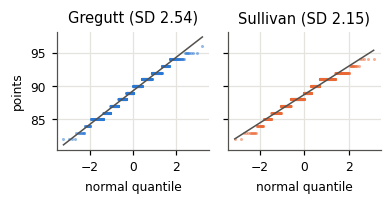

Takeaway: both critics' scores lie close to a normal line (in whole-point steps), but Sullivan's spread less (2.15 SD) than Gregutt's (2.54 SD).


In [44]:
# Q-Q plots: are each critic's scores close to normal (the F-test's assumption)?
fig, ax = plt.subplots(1, 2, figsize=(3.6, 1.9), sharey=True)
for a, x, name, c in zip(ax, (g, s), ('Gregutt', 'Sullivan'), (BLUE, ORANGE)):
    (theory, sample), (slope, intercept, _) = stats.probplot(x, dist='norm')
    a.scatter(theory, sample, s=4, color=c, alpha=0.5, linewidths=0, rasterized=True)
    a.plot(theory, slope * theory + intercept, color=GREY, linewidth=1)
    a.set(title=f'{name} (SD {x.std():.2f})', xlabel='normal quantile')
ax[0].set_ylabel('points')
fig.tight_layout()
save_fig(fig, 'fig_qq')
print("Takeaway: both critics' scores lie close to a normal line (in whole-point steps), "
      f"but Sullivan's spread less ({s.std():.2f} SD) than Gregutt's ({g.std():.2f} SD).")

**c) Result.** The variances differ significantly: Gregutt's scores are more spread out. But the CI for the SD
ratio crosses 1.2, so whether the difference **matters is unclear**. The one-variance χ² test gives a much smaller p
because it treats Gregutt's variance as known, which is why it is not the main test.

### Summary of the five tests

In [45]:
# One row per test: statistic, df, p, decision, estimate with 95% CI, and the practical verdict
def row(test, question, res, estimate, threshold, verdict):
    return {'test': test, 'question': question, 'method': res['test'], 'statistic': f"{res['stat']:,.2f}",
            'df': df_text(res['df']), 'p': f"{res['p']:.3g}", 'decision': decide(res['p']),
            'estimate (95% CI)': estimate, 'matters if': threshold, 'verdict': verdict}


def ci(res, scale=1, d=3):
    return f"{res['est'] * scale:.{d}f} ({res['lo'] * scale:.{d}f} to {res['hi'] * scale:.{d}f})"


t3 = dict(test='chi-square independence', stat=chi2_3, df=dof3, p=p3)
pd.DataFrame([
    row('T1', 'Old vs New World, $20-40', t1, ci(t1), '1 point', v1),
    row('T2', 'review length vs score', t2, ci(t2), 'r = 0.3', v2),
    row('T3', 'price band x 90+', t3, 'see band table', '5 pp per step', v3),
    row('T4', 'Gregutt vs Sullivan, 90+ share (pp)', t4, ci(t4, scale=100, d=1), '5 pp', v4),
    row('T5', 'Gregutt vs Sullivan, variance ratio', t5, ci(t5), 'SD ratio 1.2', v5),
])

,test,question,method,statistic,df,p,decision,estimate (95% CI),matters if,verdict
0,T1,"Old vs New World, $20-40",Welch t,24.64,"42,033",3.84e-133,reject H0,0.595 (0.548 to 0.643),1 point,does not matter
1,T2,review length vs score,t on Pearson r,213.07,"111,509",0,reject H0,0.538 (0.534 to 0.542),r = 0.3,matters
2,T3,price band x 90+,chi-square independence,"30,191.95",4,0,reject H0,see band table,5 pp per step,4 of 4 steps matter
3,T4,"Gregutt vs Sullivan, 90+ share (pp)",two-proportion z,4.92,-,8.85e-07,reject H0,11.4 (6.9 to 16.0),5 pp,matters
4,T5,"Gregutt vs Sullivan, variance ratio",F,1.40,"1,046, 805",5.54e-07,reject H0,1.399 (1.227 to 1.592),SD ratio 1.2,unclear


## 6. Limitations

* **Scores start at 80.** WineEnthusiast does not publish lower scores, so we only see published reviews; averages
  are pushed up and spreads down.
* **Rows are not fully independent.** Wines from one winery, or scores from one critic, share influences, so the
  p-values are too optimistic. That is why the verdicts rely on the CI vs the smallest difference that matters.
* **Association, not cause.** Longer reviews do not *cause* higher scores (critics probably write more about wines
  they like). Old vs New World (T1) is mixed up with the critic, because each critic covers different countries.
  Gregutt and Sullivan may also have been sent wines from different wineries.
* **Filled-in prices are left out.** Prices are missing more often in some countries (2.4), so those countries
  are under-represented in the tests.
* **Narrow slices.** T1 uses \$20–40 bottles; T4 and T5 use Washington \$20–40 wines from shared vintages. Other
  prices, regions and critics may behave differently.
* **Old data.** The reviews were scraped in 2017.